In [1]:
!pip install -q loguru==0.7.2

2026-11-17 09:47:20.485 | INFO     | __main__:<cell line: 0>:342 - EpsilonGreedy(p=[1.0, 2.0, 3.0, 4.0], eps0=1.0)
2026-11-17 09:47:20.488 | INFO     | __main__:<cell line: 0>:343 - ThompsonSampling(p=[1.0, 2.0, 3.0, 4.0], precision=1.0)
2026-11-17 09:47:20.492 | INFO     | __main__:experiment:191 - Running EpsilonGreedy for 20000 trials
2026-11-17 09:47:20.922 | INFO     | __main__:experiment:278 - Running ThompsonSampling for 20000 trials
2026-11-17 09:47:22.075 | INFO     | __main__:_report:297 - [EpsilonGreedy] Average reward: 3.6954
2026-11-17 09:47:22.086 | INFO     | __main__:_report:298 - [EpsilonGreedy] Average regret: 0.3090
2026-11-17 09:47:22.094 | INFO     | __main__:_report:299 - [EpsilonGreedy] Cumulative reward: 73907.23
2026-11-17 09:47:22.105 | INFO     | __main__:_report:300 - [EpsilonGreedy] Cumulative regret: 6181.00
2026-11-17 09:47:22.113 | INFO     | __main__:_report:302 - [EpsilonGreedy] Pulls per arm over 20000 trials: [2, 3, 6169, 13826]
2026-11-17 09:47:22.1

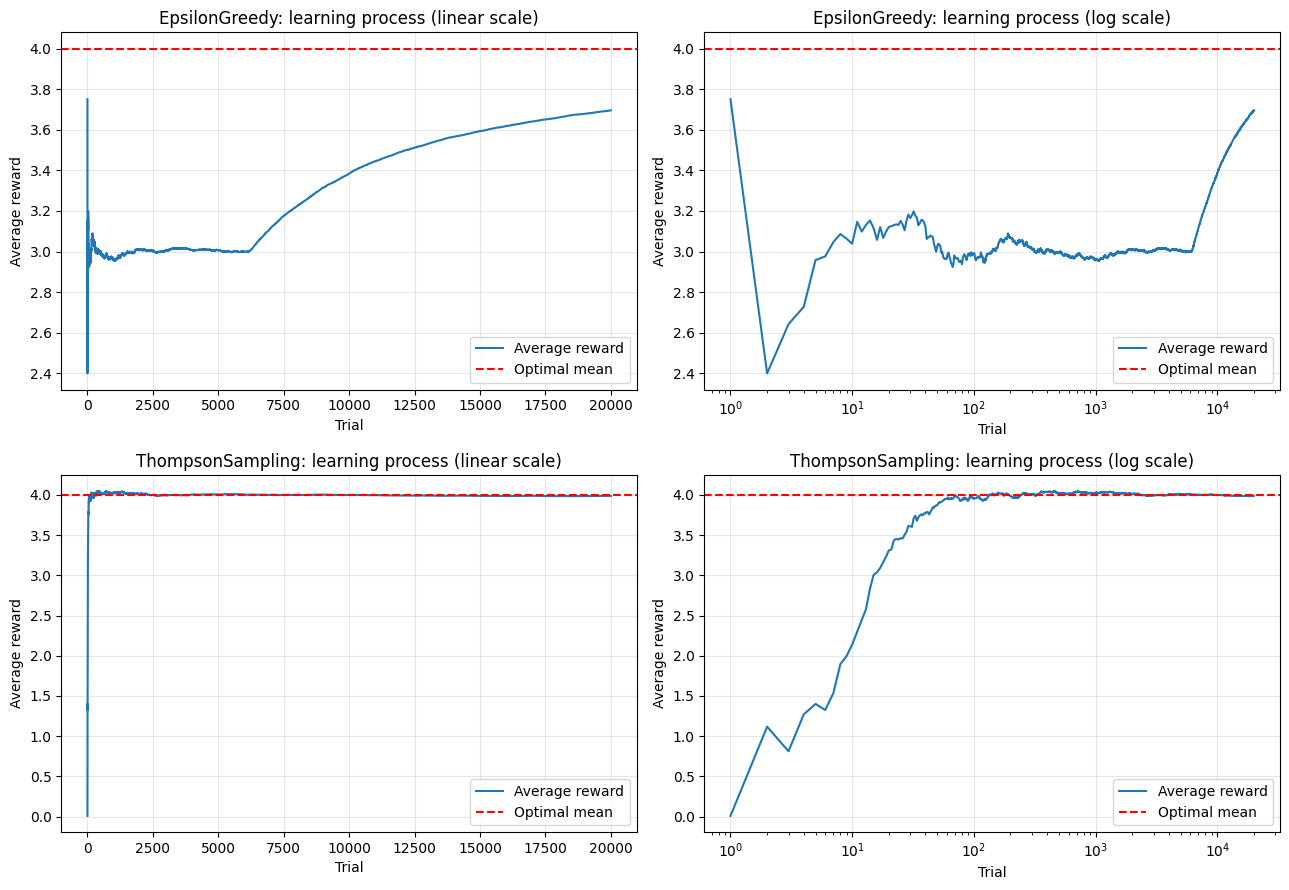

2026-11-17 09:47:25.054 | INFO     | __main__:plot1:91 - Saved plot1_learning_process.png


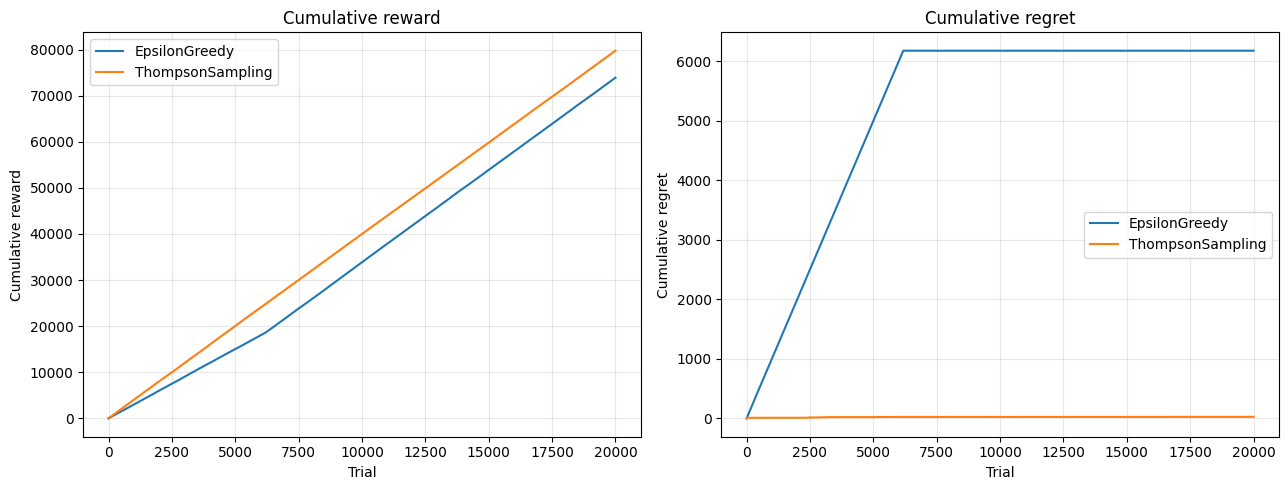

2026-11-17 09:47:26.149 | INFO     | __main__:plot2:120 - Saved plot2_comparison.png


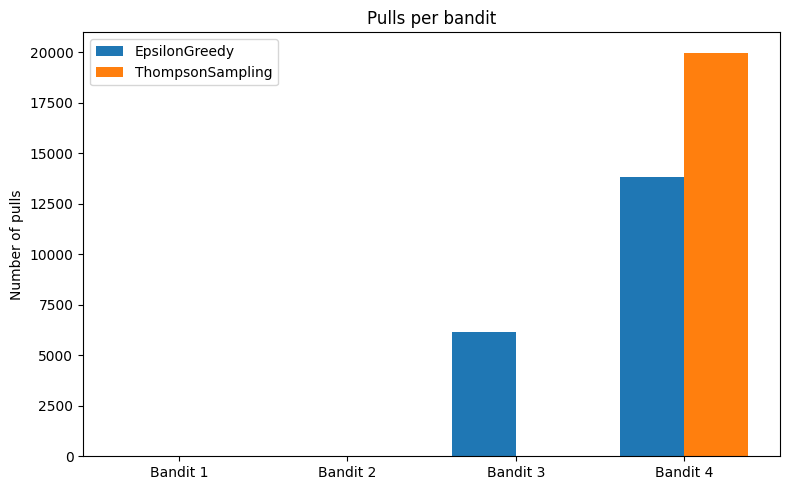

2026-11-17 09:47:26.565 | INFO     | __main__:comparison:336 - Saved comparison_per_arm.png


In [2]:
"""
A/B testing with multi-armed bandits: Epsilon-Greedy vs Thompson Sampling.

Four advertisement options (arms) with true mean rewards [1, 2, 3, 4] are
simulated for 20000 trials with each algorithm. Rewards are Gaussian with a
known precision (tau = 1 / variance), which is what Thompson Sampling with
known precision relies on.
"""
from abc import ABC, abstractmethod

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from loguru import logger

BANDIT_REWARDS = [1, 2, 3, 4]
NUM_TRIALS = 20000
TRUE_PRECISION = 1.0
SEED = 42


class Bandit(ABC):

    @abstractmethod
    def __init__(self, p):
        pass

    @abstractmethod
    def __repr__(self):
        pass

    @abstractmethod
    def pull(self):
        pass

    @abstractmethod
    def update(self):
        pass

    @abstractmethod
    def experiment(self):
        pass

    @abstractmethod
    def report(self):

        pass



class Visualization():
    """Plotting helpers for the bandit experiments."""

    def plot1(self, algorithms, filename="plot1_learning_process.png"):
        """Visualize the learning process of each algorithm (linear and log scale).

        For every algorithm, the running average reward is plotted against
        the trial number, on a linear x-axis (left) and on a log x-axis (right).
        The dashed line is the optimal mean reward.

        Parameters
        ----------
        algorithms : list of Bandit
            Algorithms that already ran ``experiment()``.
        filename : str
            Where the figure is saved.
        """
        fig, axes = plt.subplots(len(algorithms), 2, figsize=(13, 4.5 * len(algorithms)))
        axes = np.atleast_2d(axes)
        for row, algo in enumerate(algorithms):
            trials = np.arange(1, len(algo.rewards) + 1)
            avg = np.cumsum(algo.rewards) / trials
            for col, scale in enumerate(["linear", "log"]):
                ax = axes[row, col]
                ax.plot(trials, avg, label="Average reward")
                ax.axhline(max(algo.p), color="r", linestyle="--", label="Optimal mean")
                ax.set_xscale(scale)
                ax.set_title(f"{algo.name}: learning process ({scale} scale)")
                ax.set_xlabel("Trial")
                ax.set_ylabel("Average reward")
                ax.legend()
                ax.grid(alpha=0.3)
        fig.tight_layout()
        fig.savefig(filename, dpi=120)
        plt.show()
        logger.info(f"Saved {filename}")

    def plot2(self, eg, ts, filename="plot2_comparison.png"):
        """Compare cumulative rewards and cumulative regrets of both algorithms.

        Parameters
        ----------
        eg : EpsilonGreedy
            Epsilon-Greedy algorithm after ``experiment()``.
        ts : ThompsonSampling
            Thompson Sampling algorithm after ``experiment()``.
        filename : str
            Where the figure is saved.
        """
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        for algo in (eg, ts):
            axes[0].plot(np.cumsum(algo.rewards), label=algo.name)
            axes[1].plot(np.cumsum(algo.regrets), label=algo.name)
        axes[0].set_title("Cumulative reward")
        axes[1].set_title("Cumulative regret")
        for ax in axes:
            ax.set_xlabel("Trial")
            ax.legend()
            ax.grid(alpha=0.3)
        axes[0].set_ylabel("Cumulative reward")
        axes[1].set_ylabel("Cumulative regret")
        fig.tight_layout()
        fig.savefig(filename, dpi=120)
        plt.show()
        logger.info(f"Saved {filename}")



class EpsilonGreedy(Bandit):
    """Epsilon-Greedy bandit with epsilon decaying as 1/t.

    Parameters
    ----------
    p : list of float
        True mean reward of each arm.
    precision : float
        Known precision (1/variance) of the Gaussian reward noise.
    eps0 : float
        Initial epsilon; at trial t, epsilon = eps0 / t.
    """

    name = "EpsilonGreedy"

    def __init__(self, p, precision=TRUE_PRECISION, eps0=1.0, seed=SEED):
        self.p = np.asarray(p, dtype=float)
        self.k = len(p)
        self.precision = precision
        self.eps0 = eps0
        self.rng = np.random.default_rng(seed)
        self.estimates = np.zeros(self.k)  # estimated mean of each arm
        self.counts = np.zeros(self.k, dtype=int)
        self.t = 0
        self.arms = []
        self.rewards = []
        self.regrets = []

    def __repr__(self):
        return f"EpsilonGreedy(p={self.p.tolist()}, eps0={self.eps0})"

    def pull(self):
        """Choose an arm (explore with probability eps0/t) and sample its reward.

        Returns
        -------
        tuple of (int, float)
            The chosen arm and the observed reward.
        """
        self.t += 1
        epsilon = self.eps0 / self.t
        if self.rng.random() < epsilon:
            arm = int(self.rng.integers(self.k))
        else:
            arm = int(np.argmax(self.estimates))
        reward = self.rng.normal(self.p[arm], 1 / np.sqrt(self.precision))
        return arm, reward

    def update(self, arm, reward):
        """Update the running mean estimate of the chosen arm.

        Parameters
        ----------
        arm : int
            Index of the pulled arm.
        reward : float
            Observed reward.
        """
        self.counts[arm] += 1
        self.estimates[arm] += (reward - self.estimates[arm]) / self.counts[arm]
        self.arms.append(arm)
        self.rewards.append(reward)
        self.regrets.append(self.p.max() - self.p[arm])

    def experiment(self, num_trials=NUM_TRIALS):
        """Run the experiment for ``num_trials`` trials."""
        logger.info(f"Running {self.name} for {num_trials} trials")
        for _ in range(num_trials):
            arm, reward = self.pull()
            self.update(arm, reward)

    def report(self):
        """Print the average reward, average regret and cumulative totals.

        Returns
        -------
        pandas.DataFrame
            Columns ``Bandit``, ``Reward``, ``Algorithm`` for every trial.
        """
        return _report(self)



class ThompsonSampling(Bandit):
    """Thompson Sampling for Gaussian rewards with known precision.

    Each arm has a Gaussian posterior over its mean. With known reward
    precision ``tau`` and a prior N(mu0, 1/lambda0), after n observations
    with sum S the posterior is N((lambda0*mu0 + tau*S)/lambda, 1/lambda),
    where lambda = lambda0 + n*tau.

    Parameters
    ----------
    p : list of float
        True mean reward of each arm.
    precision : float
        Known precision (1/variance) of the reward noise.
    prior_mean, prior_precision : float
        Parameters of the Gaussian prior on each arm's mean.
    """

    name = "ThompsonSampling"

    def __init__(self, p, precision=TRUE_PRECISION, prior_mean=0.0,
                 prior_precision=0.01, seed=SEED + 1):
        self.p = np.asarray(p, dtype=float)
        self.k = len(p)
        self.precision = precision
        self.post_mean = np.full(self.k, prior_mean, dtype=float)
        self.post_precision = np.full(self.k, prior_precision, dtype=float)
        self.rng = np.random.default_rng(seed)
        self.arms = []
        self.rewards = []
        self.regrets = []

    def __repr__(self):
        return f"ThompsonSampling(p={self.p.tolist()}, precision={self.precision})"

    def pull(self):
        """Sample a mean from each posterior, play the best, observe its reward.

        Returns
        -------
        tuple of (int, float)
            The chosen arm and the observed reward.
        """
        samples = self.rng.normal(self.post_mean, 1 / np.sqrt(self.post_precision))
        arm = int(np.argmax(samples))
        reward = self.rng.normal(self.p[arm], 1 / np.sqrt(self.precision))
        return arm, reward

    def update(self, arm, reward):
        """Bayesian update of the chosen arm's Gaussian posterior.

        Parameters
        ----------
        arm : int
            Index of the pulled arm.
        reward : float
            Observed reward.
        """
        new_precision = self.post_precision[arm] + self.precision
        self.post_mean[arm] = (
            self.post_precision[arm] * self.post_mean[arm] + self.precision * reward
        ) / new_precision
        self.post_precision[arm] = new_precision
        self.arms.append(arm)
        self.rewards.append(reward)
        self.regrets.append(self.p.max() - self.p[arm])

    def experiment(self, num_trials=NUM_TRIALS):
        """Run the experiment for ``num_trials`` trials."""
        logger.info(f"Running {self.name} for {num_trials} trials")
        for _ in range(num_trials):
            arm, reward = self.pull()
            self.update(arm, reward)

    def report(self):
        """Print the average reward, average regret and cumulative totals.

        Returns
        -------
        pandas.DataFrame
            Columns ``Bandit``, ``Reward``, ``Algorithm`` for every trial.
        """
        return _report(self)


def _report(algo):
    """Shared reporting logic: log averages/cumulatives, return the data frame."""
    n = len(algo.rewards)
    logger.info(f"[{algo.name}] Average reward: {np.mean(algo.rewards):.4f}")
    logger.info(f"[{algo.name}] Average regret: {np.mean(algo.regrets):.4f}")
    logger.info(f"[{algo.name}] Cumulative reward: {np.sum(algo.rewards):.2f}")
    logger.info(f"[{algo.name}] Cumulative regret: {np.sum(algo.regrets):.2f}")
    counts = np.bincount(algo.arms, minlength=algo.k)
    logger.info(f"[{algo.name}] Pulls per arm over {n} trials: {counts.tolist()}")
    return pd.DataFrame({
        "Bandit": algo.arms,
        "Reward": algo.rewards,
        "Algorithm": algo.name,
    })


def comparison(eg, ts, filename="comparison_per_arm.png"):
    """Compare both algorithms visually: how often each arm was chosen.

    Complements ``Visualization.plot2`` (cumulative reward / regret) by showing
    that Thompson Sampling concentrates its pulls on the best arm faster.

    Parameters
    ----------
    eg : EpsilonGreedy
    ts : ThompsonSampling
    filename : str
        Where the figure is saved.
    """
    fig, ax = plt.subplots(figsize=(8, 5))
    width = 0.38
    x = np.arange(eg.k)
    ax.bar(x - width / 2, np.bincount(eg.arms, minlength=eg.k), width, label=eg.name)
    ax.bar(x + width / 2, np.bincount(ts.arms, minlength=ts.k), width, label=ts.name)
    ax.set_xticks(x)
    ax.set_xticklabels([f"Bandit {int(r)}" for r in eg.p])
    ax.set_ylabel("Number of pulls")
    ax.set_title("Pulls per bandit")
    ax.legend()
    fig.tight_layout()
    fig.savefig(filename, dpi=120)
    plt.show()
    logger.info(f"Saved {filename}")


if __name__ == '__main__':
    eg = EpsilonGreedy(BANDIT_REWARDS)
    ts = ThompsonSampling(BANDIT_REWARDS)
    logger.info(f"{eg}")
    logger.info(f"{ts}")

    eg.experiment()
    ts.experiment()

    df = pd.concat([eg.report(), ts.report()], ignore_index=True)
    df.to_csv("rewards.csv", index=False)
    logger.info(f"Saved rewards.csv with {len(df)} rows")

    viz = Visualization()
    viz.plot1([eg, ts])
    viz.plot2(eg, ts)
    comparison(eg, ts)

BONUS: Suggested Implementation Plan

1. Observed limitations of the current implementation

In the experiment (20,000 trials, bandit rewards [1, 2, 3, 4]), Thompson Sampling clearly outperformed Epsilon-Greedy: its cumulative regret was about 26, compared with about 6,181 for Epsilon-Greedy. The main reasons are:

- With epsilon decaying as 1/t, Epsilon-Greedy almost stops exploring after the first few trials. It pulled the two worst arms only 2 and 3 times and then spent thousands of pulls on the second-best arm, because its estimates for the best arm were never tested enough.
- Each algorithm is run only once, so the result depends on the random seed. A single lucky or unlucky early pull can change the outcome of Epsilon-Greedy considerably.
- The reward precision is assumed to be known, which is rarely the case in a real A/B test.

2. Proposed improvements

a) Slower epsilon decay. Use epsilon_t = min(1, c*K / t) or epsilon_t = eps0 / sqrt(t), where K is the number of arms. This keeps exploring longer and makes it much more likely that the best arm is found.

b) Optimistic initialization. Start every arm's estimated mean at a high value so that each arm is tried several times before the algorithm commits to one.

c) Multiple runs. Repeat each experiment with 50-100 different random seeds and plot the average cumulative regret with a confidence band. This shows whether the difference between the algorithms is real and not caused by one seed.

d) Unknown variance. Replace the known-precision Gaussian model in Thompson Sampling with a Normal-Gamma posterior, so that both the mean and the precision of each arm are learned from data.

e) Additional baseline. Add UCB1 as a third algorithm to make the comparison more complete.

f) Better visualization. Plot cumulative regret on a log scale. A good algorithm should show regret growing roughly logarithmically in the number of trials.

g) Code quality. Move the shared logic (pull loop, bookkeeping, reporting) into the Bandit base class to avoid duplication, store all settings (rewards, number of trials, epsilon, precision, seed) in one configuration object, and add unit tests, for example checking that the posterior mean in Thompson Sampling converges to the true arm mean.

3. Expected result

These changes should make Epsilon-Greedy much more reliable, make the comparison statistically meaningful, and make the code easier to maintain and extend.
